# Stats 21 - HW4: Palmer Penguins (My Old Enemy), Summaries, and Plots

## [Connor Alvarez]

Practice turning a question into a pandas analysis and a clearly explained plot.
The central questions are: **Which records contribute, what does a summary mean,
and what can we learn from comparing groups?**


## Academic Integrity

This homework is practice for building your own understanding. Work through the problems, check your reasoning, and use permitted help to support your learning.

Replace `[Connor Alvarez]` to acknowledge the following:

> I, [Connor Alavarez], agree to follow the course academic integrity policies and the Stats 21 AI and Collaboration Policy. My submitted work reflects my own thinking and understanding, and I can explain my code and results.

**Acknowledgments and AI disclosure:** Credit any people or sources you relied on, and disclose any AI assistance (including hints, debugging, or editing). Briefly state which problems they helped with and how, or write "None".

[Your acknowledgments and AI disclosure here.]

---

### Setup and submission

- Use pandas for data preparation, Matplotlib for Part 6, seaborn for Parts 7 and 8, and either pandas plotting or Matplotlib for Part 9.
- Review lectures 13–15 and 17–18.
- Complete the code and short written responses (1–2 sentences are usually enough unless specified otherwise). Use code to calculate requested results rather than hardcoding values.
- Keep `penguins.csv` in the same directory as this notebook. Use this supplied file rather than loading the dataset from seaborn, as this version includes the `year` column.
- Before submitting, restart the kernel and run all cells from top to bottom so all tables, plots, and written responses are visible.
- Export to HTML, print to a letter-sized PDF, and submit the PDF to Gradescope with pages assigned to each question. Submit your completed `.ipynb` file as well.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)


### About the data

Each row represents a single penguin record. `species`, `island`, and `sex` describe groups, and `year` records the study year. Bill length, bill depth, and flipper length are measured in millimeters; body mass is in grams.

The data were collected by Kristen Gorman and the Palmer Station LTER program. See the [Palmer Penguins data dictionary](https://allisonhorst.github.io/palmerpenguins/reference/penguins.html) for details.


In [3]:
penguins = pd.read_csv("penguins.csv")

# Use these four physical measurements for the requested numeric summaries.
measurement_cols = [
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"
]
species_order = ["Adelie", "Chinstrap", "Gentoo"]

penguins.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Part 1) Inspect the data

Use the original `penguins` table.

a. Display its shape and state what one row represents.

b. Display the column names and data types. Which numeric column records the study year rather than a physical measurement? Why shouldn't data type alone determine which columns belong in a summary of penguin size?

c. Display the number of missing values in each column.

d. Count records by `species` and by `sex`, including missing values (`value_counts(dropna=False)`). Verify that each set of counts adds up to the total number of rows.


In [4]:
# Part 1: inspect the original table and display the requested counts.
#(a)
print(penguins.shape)

#(b)
print(penguins.columns)
print(penguins.dtypes)

#(c)
print(penguins.isna().sum())

#(d)
species_ct = penguins["species"].value_counts(dropna=False)
sex_ct = penguins["sex"].value_counts(dropna=False)

print(species_ct)
print(sex_ct)


(344, 8)
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
sex
male      168
female    165
NaN        11
Name: count, dtype: int64


**Written response:**

[Write your interpretation here.]

- (a): One row represents 1 observation (penguin) and their attributes
- (b): The column `year` recorded when the penguin was studied. Data type alone isn't sufficient because the numeric variable can describe time rather than a physical measurement.
- (c): There are 2 missing values each for `bill length`, `bill depth`, `flipper length`, and `body mass`. There are 11 for `sex`.
- (d): Both `species` and `sex` count including the missing values amount to the total of 344.


### Part 2) Missing data: choose rows for the question

Do not modify the original `penguins` DataFrame in place.

a. Create `penguins_clean` by dropping rows missing any of the four `measurement_cols` or `sex` (use `.dropna(subset=...).copy()`). Display its shape and the number of rows removed.

b. Create `penguins_bill` from `penguins` by dropping only rows missing `bill_length_mm`, `bill_depth_mm`, or `species`, keeping all columns. Display its shape and how many more records it retains than `penguins_clean`.

c. For a plot of bill length versus bill depth colored by species, which subset is more appropriate? Explain why a missing value for `sex` should or should not exclude a record from this plot.

*Note: `penguins_clean` is only for comparison here. In the parts that follow, filter `penguins` (or use `penguins_bill` where specified) based only on the variables needed for that question.*


In [5]:
# Part 2: construct the two subsets and compare their row counts.
#(a)
penguins_clean = penguins.dropna(subset = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"]).copy()
print("The Shape of `penguins_clean` is :", penguins_clean.shape)
print("Rows removed:", len(penguins) - len(penguins_clean))

#(b)
penguins_bill = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm", "species"]).copy()
print("The Shape of `penguins_bill` is :", penguins_bill.shape)
print("Rows retained over `penguins_clean`:", len(penguins_bill) - len(penguins_clean))


The Shape of `penguins_clean` is : (333, 8)
Rows removed: 11
The Shape of `penguins_bill` is : (342, 8)
Rows retained over `penguins_clean`: 9


**Written response:**

- (a) `penguins_clean` dropped 11 rows
- (b) `penguins_bill` dropped 9 rows
- (c) We should use `penguins_bill` because even when there's a missing `sex` value, it does not prevent us from plotting the penguins physical measurements or recorded species. That data is still pertinent, despite missing the value for `sex`.


### Part 3) Numeric summaries and a small wrangling task

Use `penguins`, retaining rows with missing values.

a. Use `.describe()` on `measurement_cols` to show the count, mean, standard deviation, minimum, quartiles, and maximum. Explain what `count` represents and why it can differ from the total number of rows.

b. Compute the mean and standard deviation of `measurement_cols` within each species.

c. Add a `body_mass_kg` column to `penguins` by converting grams to kilograms. Filter for Gentoo penguins from 2008 with a recorded body mass. Display the total number of matching records, and show `species`, `island`, `year`, and `body_mass_kg` for the five heaviest penguins sorted from heaviest to lightest.


In [6]:
# Part 3: summarize measurements, create kilograms, then filter/select/sort.

#(a)
print(penguins[measurement_cols].describe())

#(b)
print(penguins.groupby("species")[measurement_cols].agg(["mean", "std"]))

#(c)
penguins["body_mass_kg"] = penguins["body_mass_g"]/1000

#guess I should make this an object
Gentoo_2008_w_mass = penguins.loc[
    (penguins["species"] == "Gentoo") &
    (penguins["year"] == 2008) &
    penguins["body_mass_kg"].notna(),
    ["species", "island", "year", "body_mass_kg"]
]

print("Matching records:", len(Gentoo_2008_w_mass))
Gentoo_2008_w_mass.sort_values("body_mass_kg", ascending=False).head(5)


       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count         342.000        342.000            342.000      342.000
mean           43.922         17.151            200.915     4201.754
std             5.460          1.975             14.062      801.955
min            32.100         13.100            172.000     2700.000
25%            39.225         15.600            190.000     3550.000
50%            44.450         17.300            197.000     4050.000
75%            48.500         18.700            213.000     4750.000
max            59.600         21.500            231.000     6300.000
          bill_length_mm        bill_depth_mm        flipper_length_mm         \
                    mean    std          mean    std              mean    std   
species                                                                         
Adelie            38.791  2.663        18.346  1.217           189.954  6.539   
Chinstrap         48.834  3.339        18.421  1.135   

,species,island,year,body_mass_kg
229,Gentoo,Biscoe,2008,6.00
231,Gentoo,Biscoe,2008,5.95
219,Gentoo,Biscoe,2008,5.80
227,Gentoo,Biscoe,2008,5.80
193,Gentoo,Biscoe,2008,5.70


**Written response:**

[Write your interpretation here.]

-(a) The count does not return the total 344 because it displays the nonmissing values in each column. If we were to take a different subset such as `sex`, it would would be 11 values lower than the total from the missing values.
-(b) A quick look at the mean and standard deviation across the `measurement_cols` shows some overlay in physical measurements that might lead to issues later of discerning a penguin species from one physical attribute. A transformation might be necessary.


### Part 4) Two-way grouped summaries

Use `penguins` and group by `species` and `sex`, keeping missing-sex groups with `groupby(..., dropna=False)`.

a. Produce a summary table with one row per species/sex combination that includes the total row count (`n_penguins`, using `size`) and the mean and nonmissing count (`count`) for each of the four `measurement_cols`.

b. Verify that `n_penguins` sums to the total number of rows in `penguins`. For one of the unknown-sex groups, compare `n_penguins` with its nonmissing `body_mass_g` count. Explain why they differ and which count serves as the denominator when computing mean body mass.

c. Among groups with recorded sex, identify the species/sex group with the largest mean body mass and display its summary row. Does having the largest group mean imply that every penguin in that group is heavier than every penguin in the other groups? Explain briefly.


In [7]:
# Part 4: keep unknown-sex groups and distinguish size from count.
# (a)
summary_penguins = (penguins.groupby(["species", "sex"], dropna=False).agg(
        n_penguins=("species", "size"),
        bill_length_mean=("bill_length_mm", "mean"),
        bill_length_count=("bill_length_mm", "count"),
        bill_depth_mean=("bill_depth_mm", "mean"),
        bill_depth_count=("bill_depth_mm", "count"),
        flipper_length_mean=("flipper_length_mm", "mean"),
        flipper_length_count=("flipper_length_mm", "count"),
        body_mass_mean=("body_mass_g", "mean"),
        body_mass_count=("body_mass_g", "count")
    )

    # needed this to reset index for # (b)
    .reset_index()
)

# (b)
print(summary_penguins["n_penguins"].sum(), len(penguins))

print(summary_penguins.loc[
    summary_penguins["sex"].isna(),
    ["species", "sex", "n_penguins", "body_mass_count"]
])

# (c)
print(summary_penguins.loc[
    summary_penguins["sex"].notna()
].sort_values("body_mass_mean", ascending=False
              ).head(1))


344 344
  species  sex  n_penguins  body_mass_count
2  Adelie  NaN           6                5
7  Gentoo  NaN           5                4
  species   sex  n_penguins  bill_length_mean  bill_length_count  \
6  Gentoo  male          61            49.474                 61   

   bill_depth_mean  bill_depth_count  flipper_length_mean  \
6           15.718                61              221.541   

   flipper_length_count  body_mass_mean  body_mass_count  
6                    61        5484.836               61  


**Written response:**

[Write your interpretation here.]

-(b) So `n_penguins` and `penguins` have the same length of 344. For *Adelie*, unknown sex in `n_penguins` is 6, but the `body_mass_count` is 5. Therefore mean body mass uses 5 and not 6 because `body_mass_count` returns 5, despite `sex` missing an additional observation.

-(c) *Male Gentoo* penguins have the largest mean body mass. However, this does not mean that every male Gentoo is heavier than every penguin in another group. There could be penguins in other groups that have a higher body mass but isn't reflected in the mean group averages.


### Part 5) Correlations and Simpson's paradox

Use `penguins_bill` and `measurement_cols`.

a. Compute the Pearson correlation matrix for the four measurements, first across all penguins pooled together, and then separately within each species (`groupby("species")[measurement_cols].corr()`).

b. Focus on **bill length and bill depth**. Create a compact summary table showing their pooled correlation, their correlation within each species, and the number of paired records used in each calculation.

c. Compare the signs of the correlations. A *Simpson's paradox reversal* occurs when the pooled association has the opposite sign from the association within each individual group. State whether your results show this reversal, citing the correlation values.


In [8]:
# Part 5: show the correlation matrices and a compact bill-pair comparison.

#(a)
print(penguins_bill[measurement_cols].corr())

print(penguins_bill.groupby("species")[measurement_cols].corr())

#(b)
# making a subset like measurement_col
bill_cols = ["bill_length_mm", "bill_depth_mm"]

print(penguins_bill[bill_cols].corr())

print(penguins_bill.groupby("species")[bill_cols].corr())
penguins_bill.groupby("species").size()


#(c)




                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.235              0.656   
bill_depth_mm              -0.235          1.000             -0.584   
flipper_length_mm           0.656         -0.584              1.000   
body_mass_g                 0.595         -0.472              0.871   

                   body_mass_g  
bill_length_mm           0.595  
bill_depth_mm           -0.472  
flipper_length_mm        0.871  
body_mass_g              1.000  
                             bill_length_mm  bill_depth_mm  flipper_length_mm  \
species                                                                         
Adelie    bill_length_mm              1.000          0.391              0.326   
          bill_depth_mm               0.391          1.000              0.308   
          flipper_length_mm           0.326          0.308              1.000   
          body_mass_g                 0.549          0.576              0.

species
Adelie       151
Chinstrap     68
Gentoo       123
dtype: int64

**Written response:**

[Write your interpretation here.]

- (c) The Simpson's paradox reversal is shown here because if pooled together, the correlation is `-0.235` while across `species` it shows a positive correlation. This means that pooling species together brings the correlation down because the differences between species affect the overall pattern.



### Part 6) Matplotlib histograms of body mass by species

Use rows of `penguins` with nonmissing `body_mass_g` and `species`.

a. Use `plt.subplots(1, 3, ...)` and `ax.hist(...)` to create one panel per species in `species_order`. Share the x- and y-axes and pass the same explicit bin edges (e.g., `range(2500, 6501, 500)`) to all three panels.

b. Plot counts, label body mass in grams, and include each species' sample size ($n$) in its panel title. Report the total number of included and excluded records.

c. In two sentences, compare the distributions across species and explain why a taller histogram can reflect sample size as well as distribution shape. If you set `density=True`, would the total area of the bars or the sum of the bar heights equal 1?


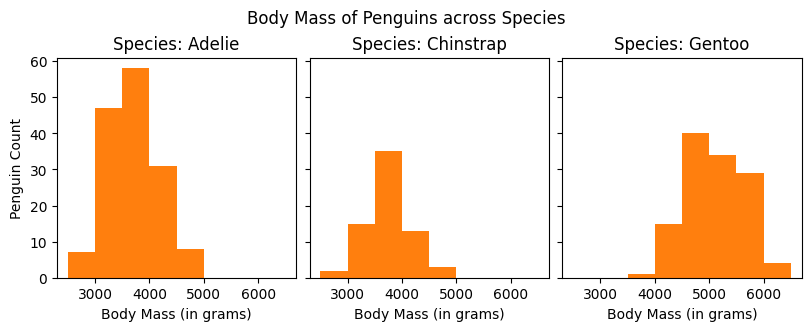

In [9]:
# Part 6: choose records, then build three Matplotlib histogram panels.

# (a)
agc = ["Adelie", "Chinstrap", "Gentoo"]
complete_mass = penguins.dropna(subset = ["body_mass_g", "species"]).copy()
bins = range(2500, 6501, 500)

fig, axes = plt.subplots(1, 3, figsize=(8, 3.2),
                         sharex=True, sharey=True, layout="constrained")

for ax, species in zip(axes, agc):
    subset = complete_mass.loc[complete_mass["species"] == species]
    ax.hist(subset["body_mass_g"], bins = bins)

# (b)
for ax, species in zip(axes, agc):
    subset = complete_mass.loc[complete_mass["species"] == species]
    ax.hist(subset["body_mass_g"], bins = bins)
    ax.set_title(f"Species: {species}")
    ax.set_xlabel("Body Mass (in grams)")
axes[0].set_ylabel("Penguin Count")
fig.suptitle("Body Mass of Penguins across Species")    
plt.show()
# (a)


**Written response:**

[Write your interpretation here.]

-(c) Gentoo penguins have greater body mass, while Adelia and Chinstrap have more similar mass.


### Part 7) Seaborn boxplots of flipper length

Use rows of `penguins` with nonmissing `flipper_length_mm` and `species`.

a. Create a Matplotlib `Axes` and pass it to `sns.boxplot(..., ax=ax)` with `species` (in `species_order`) on the x-axis and `flipper_length_mm` on the y-axis. Report the included/excluded record counts and sample sizes by species.

b. In 2–3 sentences, explain what the box and center line represent, and compare the medians and middle-50% spreads across species. Does a point plotted beyond the whiskers necessarily indicate a data error? Explain briefly.


Included: 342 Excluded: 2


C:\Users\mango\AppData\Local\Temp\ipykernel_20560\708872207.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Species", loc="upper left", bbox_to_anchor=(1.02, 1))


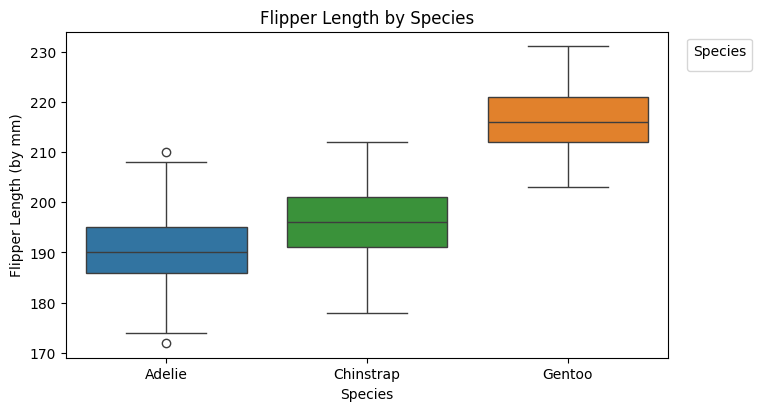

In [10]:
# Part 7: draw seaborn boxplots on a Matplotlib Axes.

# (a)
#recycling agc
complete_flipper = penguins.dropna(subset=["flipper_length_mm", "species"]).copy()

print("Included:", len(complete_flipper), "Excluded:", len(penguins) - len(complete_flipper))

box_fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
sns.boxplot(data=complete_flipper, x="species", y="flipper_length_mm", hue="species",
            order=agc, ax=ax)
ax.set(title="Flipper Length by Species",
       xlabel="Species", ylabel="Flipper Length (by mm)")
ax.legend(title="Species", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()




**Written response:**

[Write your interpretation here.]

-(b) The center line in each box is the median and the box covers the IQR. THe whiskers show values that are outside the IQR but do not qualify for an outlier but dots outside the whisker are outliers. There are some overlap between Adelie and Chinstrap species, but Gentoo are distinctly higher than the both. A point outside the whisker does not necessarily mean the data is incorrect.

### Part 8) Scatterplot and fitted lines: bill length versus bill depth

Use `penguins_bill`.

a. Plot `bill_length_mm` (x) versus `bill_depth_mm` (y), colored by `species`, with a separate linear regression line for each species. Include a legend and report the number of included and excluded records.

*Hint: `sns.lmplot(data=..., x=..., y=..., hue="species", ci=None)` plots both the points and fitted lines. Because `lmplot` creates its own figure-level `FacetGrid`, use `g.set_axis_labels(...)` and `g.figure.suptitle(...)` to label the plot (or loop over species with `sns.regplot`).*

b. In 3–4 sentences, explain what a point and a fitted line represent. Connect the slopes of the within-species lines to your correlations in Part 5, and use the relative positions of the three species clusters to explain why the pooled correlation has the opposite sign. Does this plot show that changing a penguin's bill length causes its bill depth to change?


Included: 342 Excluded: 2


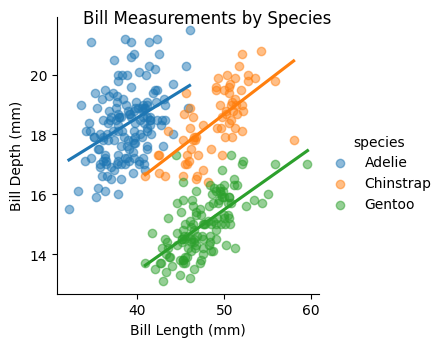

In [11]:
# Part 8: draw paired measurements and separate fitted lines by species.

# (a)
print("Included:", len(penguins_bill), "Excluded:", len(penguins) - len(penguins_bill))


g = sns.lmplot(data=penguins_bill, x="bill_length_mm", y="bill_depth_mm", hue="species", hue_order=agc,
                ci=None, scatter_kws={"alpha": 0.5},
                height = 3.5)
g.set_axis_labels("Bill Length (mm)", "Bill Depth (mm)")
g.figure.suptitle("Bill Measurements by Species")
plt.show()



**Written response:**

[Write your interpretation here.]

-(b) The graph plots all three species with Bill Length vs Bill Depth. Each point is an observation separated by color. Each cluster is slightly different and have their own regression line. Question 5 correlations are reflect here. However, when pooled, likein Question 5, we see that there is a negative correlation because it tries to fit OLS on a across the different clusters.


### Part 9) Stacked bars: recorded sex proportions by species

Create `penguins_sex` from `penguins` by keeping rows with nonmissing `species` and `sex`.

a. Use `pd.crosstab(...)` to create a species-by-sex count table, then normalize each row to proportions using `.div(..., axis=0)`. Display both tables and verify that each row of proportions sums to 1.

b. Create a stacked bar chart in `species_order` showing the male and female proportions for each species (using `.plot.bar(stacked=True, ax=ax)` or `ax.bar(..., bottom=...)`). Label the y-axis as a proportion and include a legend.

c. Report the number of included and excluded records per species, and include the sample sizes ($n$) in your chart labels or title. Briefly compare the sex proportions across species, and explain why bars of equal total height (1.0) do not imply equal sample sizes.

d. In one sentence, explain what would happen if you reset the index of your 3-row count table and passed it directly to `sns.countplot(data=..., x="species")`.


sex        female  male
species                
Adelie         73    73
Chinstrap      34    34
Gentoo         58    61
sex        female   male
species                 
Adelie      0.500  0.500
Chinstrap   0.500  0.500
Gentoo      0.487  0.513


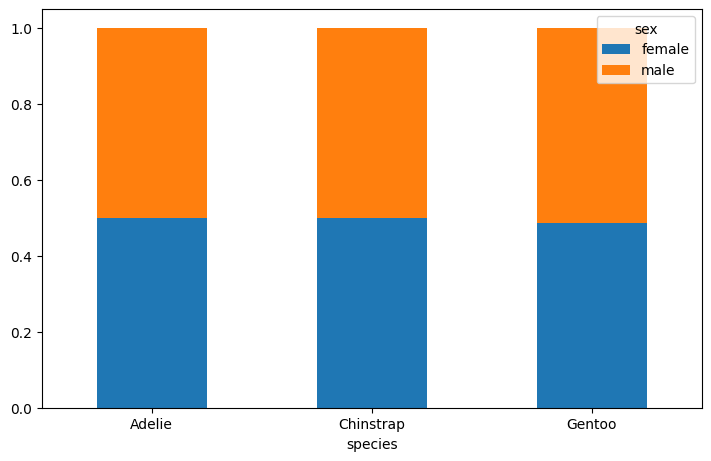

Included: species
Adelie       146
Chinstrap     68
Gentoo       119
dtype: int64 Excluded: species
Adelie       6
Chinstrap    0
Gentoo       5
dtype: int64


In [ ]:
# Part 9: calculate counts and proportions before drawing the stacked bars.

# (a)
penguins_sex = penguins.dropna(subset = ["species", "sex"]).copy()

species_by_sex = pd.crosstab(
    penguins_sex["species"], penguins_sex["sex"]
)
print(species_by_sex)

sex_prop = species_by_sex.div(species_by_sex.sum(axis=1), axis=0)
print(sex_prop)

# (b)
fig, axes = plt.subplots(figsize=(7, 4.5), layout="constrained")
sex_prop.plot.bar(stacked=True, ax=axes, rot=0)

ax.set(xlabel="Species", ylabel="Proportion")
ax.legend(title="Sex")
plt.show()


# (c)
count_by_sex = penguins.groupby("species").size()
included = species_by_sex.sum(axis=1)
excluded = count_by_sex - included

print("Included:", included, "Excluded:", excluded)



**Written response:**

[Write your interpretation here.]

-(c) Adelie and Chinstrap have a 50:50 split for female to male. Gentoo also has this but it's moreso 48.7% female to 51.3% male split. Every bar reaches 1 becahse the proportions are calculated within species. Just because the bars look equal does not mean equal sample sizes, we just scaled them on the same proportions of 1.

-(d) Resetting the index would leave one row per species in the summary table. Thus it would just show a count of 1 for each species because it would count summary rows rather than the observations.


### Before submitting

Restart the kernel and run all cells. Make sure all tables, figures, and written responses are visible, and double-check that you completed the academic integrity acknowledgment at the top of the notebook.

Useful references: [pandas aggregation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html),
[pandas correlations](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html),
[Matplotlib subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html),
and [seaborn regression plots](https://seaborn.pydata.org/generated/seaborn.lmplot.html).
